# Week 11B: LAS → DSM in Center City and University City

Download **two Philadelphia LAS tiles**, use **PDAL** to turn each into a digital surface model (DSM), and visualize the resulting GeoTIFF rasters. These are small case-study footprints, not complete neighborhood coverage or a citywide analysis.

A DSM records surface elevation, including roofs, trees, and ground. It is different from a bare-earth DTM and from building height above ground.

## 1. Keep using `geospatial`

**Do not create another environment.** Select your existing `geospatial` notebook kernel. This notebook uses `pdal`, `rasterio`, `pyproj`, `numpy`, `pandas`, `matplotlib`, and `requests`; all are already installed in the instructor's checked `geospatial` environment. **No new modules are needed there.** We read LAS metadata through PDAL, so `laspy` is not required.

If any are missing from your own environment, install only those packages into the existing environment. The conda package for `import pdal` is **`python-pdal`**:

```bash
conda activate geospatial
# Only if missing:
conda install -n geospatial -c conda-forge python-pdal rasterio pyproj numpy pandas matplotlib requests
```

Run the notebook from this lab directory or from the course repository root. Raw LAS downloads are kept in a cache outside the website. Set `MUSA550_CACHE` to change that location. The two files total about **2.09 GB**; ensure sufficient disk space and allow time for the first download.

In [1]:
from pathlib import Path
import json
import math
import os
import sys

import pdal
import rasterio
from rasterio.plot import show
from pyproj import CRS, Transformer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
import requests

LAB = Path.cwd()
if not (LAB / "lecture-11B.ipynb").exists():
    LAB = LAB / "public/labs/week11-large-data-viz-lidar"
assert (LAB / "lecture-11B.ipynb").exists(), "Run from the lab directory or repository root."
CACHE = Path(os.environ.get("MUSA550_CACHE", Path.home() / ".cache/musa550-week11"))
RAW = CACHE / "raw"
OUT = LAB / "outputs/lidar/case_studies"
RAW.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
print("Python:", sys.executable)
print("PDAL:", pdal.__version__)
print("Raw LAS cache:", RAW)

Python: /opt/anaconda3/envs/geospatial/bin/python
PDAL: 3.5.3
Raw LAS cache: /tmp/week11-lidar-raw


## 2. Choose two neighborhood examples

The [PASDA provider tile index](https://www.pasda.psu.edu/download/phillyLiDAR/2022/Metadata_and_Reports/ESRI_shapefiles/) identifies the following 3,000 × 3,000 US-survey-foot footprints (about 914 × 914 m). We selected them using the provider polygons, not file-number guesses.

- **University City:** `Philadelphia_394.las`, an eastern University City / campus-area example.
- **Center City:** `Philadelphia_456.las`, a central downtown example near City Hall.

These are teaching footprints rather than official neighborhood boundaries. The 2022 directory is a distribution label; it does not establish the acquisition date. Only these two LAS files are downloaded from the [classified LAS directory](https://www.pasda.psu.edu/download/phillyLiDAR/2022/LAS/Classified_LAS/).

In [2]:
BASE_URL = "https://www.pasda.psu.edu/download/phillyLiDAR/2022/LAS/Classified_LAS/"
cases = [
    {"zone": "University City", "name": "Philadelphia_394.las", "bytes": 1_090_289_145,
     "bounds": [2685000, 235000, 2688000, 238000]},
    {"zone": "Center City", "name": "Philadelphia_456.las", "bytes": 997_092_345,
     "bounds": [2691000, 235000, 2694000, 238000]},
]
pd.DataFrame(cases)[["zone", "name", "bytes"]]

,zone,name,bytes
0,University City,Philadelphia_394.las,1090289145
1,Center City,Philadelphia_456.las,997092345


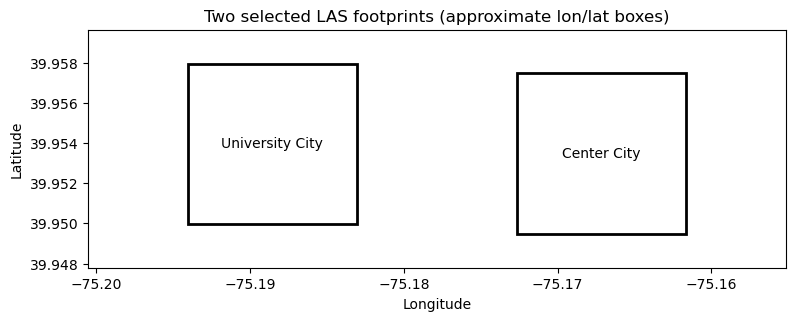

In [3]:
# Show the selected footprints in longitude/latitude before downloading.
to_lonlat = Transformer.from_crs("EPSG:6565", "EPSG:4326", always_xy=True)
fig, ax = plt.subplots(figsize=(9, 4))
for case in cases:
    left, bottom, right, top = case["bounds"]
    west, south = to_lonlat.transform(left, bottom)
    east, north = to_lonlat.transform(right, top)
    ax.add_patch(Rectangle((west, south), east-west, north-south,
                           fill=False, linewidth=2))
    ax.text((west+east)/2, (south+north)/2, case["zone"], ha="center", va="center")
ax.autoscale_view()
ax.margins(0.2)
ax.set(xlabel="Longitude", ylabel="Latitude", title="Two selected LAS footprints (approximate lon/lat boxes)")
ax.set_aspect(1 / np.cos(np.deg2rad(39.95)))
plt.show()

### Download LAS files with Python

Stream each response to disk instead of loading a gigabyte into memory. Write a temporary `.part` file, check the provider's byte size, then rename it. Reruns reuse complete cached files. A failed download can be rerun; this example restarts the incomplete file.

In [4]:
def download_las(case):
    destination = RAW / case["name"]
    if destination.exists() and destination.stat().st_size == case["bytes"]:
        print("Using cached:", destination.name)
        return destination
    temporary = destination.with_suffix(".las.part")
    print("Downloading:", case["name"])
    with requests.get(BASE_URL + case["name"], stream=True, timeout=(30, 180)) as response:
        response.raise_for_status()
        with temporary.open("wb") as stream:
            for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
                if chunk:
                    stream.write(chunk)
    if temporary.stat().st_size != case["bytes"]:
        raise ValueError(f"Unexpected download size: {temporary}. Check the provider and retry.")
    temporary.replace(destination)
    return destination

las_paths = [download_las(case) for case in cases]

Using cached: Philadelphia_394.las
Using cached: Philadelphia_456.las


## 3. Read CRS and elevation units with PDAL

`quickinfo` reads the LAS header without loading the whole point cloud. These provider files use a compound CRS: horizontal Pennsylvania South coordinates and a vertical height reference. Read the actual CRS rather than assigning latitude/longitude.

We retain native horizontal coordinates, convert elevations to meters using the vertical CRS, and choose a **1 m** pixel converted to native XY units. Unit conversion does not change the vertical datum.

In [5]:
infos = []
for path in las_paths:
    reader = pdal.Pipeline(json.dumps([{"type": "readers.las", "filename": str(path)}]))
    header = reader.quickinfo["readers.las"]
    crs = CRS.from_wkt(header["metadata"]["srs"]["compoundwkt"])
    if not crs.is_compound:
        raise ValueError("Expected a horizontal + vertical CRS; inspect the LAS metadata.")
    horizontal, vertical = crs.sub_crs_list[:2]
    if horizontal.is_bound:
        horizontal = horizontal.source_crs
    if not horizontal.is_projected:
        raise ValueError("Expected projected XY coordinates.")
    infos.append({"points": header["num_points"],
                  "horizontal": horizontal, "vertical": vertical,
                  "xy_to_m": horizontal.axis_info[0].unit_conversion_factor,
                  "z_to_m": vertical.axis_info[0].unit_conversion_factor})

pd.DataFrame([{"zone": case["zone"], "points": info["points"],
               "horizontal_crs": info["horizontal"].name,
               "xy_units": info["horizontal"].axis_info[0].unit_name,
               "vertical_crs": info["vertical"].name,
               "z_units": info["vertical"].axis_info[0].unit_name}
              for case, info in zip(cases, infos)])

,zone,points,horizontal_crs,xy_units,vertical_crs,z_units
0,University City,36291327,NAD83(2011) / Pennsylvania South (ftUS),US Survey Foot,NAVD88 height (ftUS) - US Geoid Model of 2018,US Survey Foot
1,Center City,33187641,NAD83(2011) / Pennsylvania South (ftUS),US Survey Foot,NAVD88 height (ftUS) - US Geoid Model of 2018,US Survey Foot


## 4. Convert each LAS into a DSM with PDAL

The visible pipeline reads one LAS file, keeps first returns, excludes low/high noise (classes 7/18) and withheld points, converts Z to meters, and writes **maximum elevation per pixel** to a Float32 GeoTIFF.

`binmode=True` uses only points inside each cell; `window_size=0` leaves gaps unfilled. NoData is −9999, not zero. This simple first-return maximum is an instructional DSM: remaining outliers can affect roofs and canopy peaks. It is not a ground-only elevation model.

Each writer is restricted to its selected tile footprint. Sequential streaming avoids holding all points from both files in memory, although the raster accumulator still requires memory. We save the pipeline JSON beside each raster for inspection. See the [PDAL GDAL writer documentation](https://pdal.io/en/stable/stages/writers.gdal.html).

In [6]:
CELL_SIZE_M = 1.0
NODATA = -9999.0

def make_dsm_pipeline(path, case, info, destination):
    resolution = CELL_SIZE_M / info["xy_to_m"]
    left, bottom, right, top = case["bounds"]
    origin_x = math.floor(left / resolution) * resolution
    origin_y = math.floor(bottom / resolution) * resolution
    return {"pipeline": [
        {"type": "readers.las", "filename": str(path)},
        {"type": "filters.crop", "bounds": f"([{left},{right}],[{bottom},{top}])"},
        {"type": "filters.expression", "expression":
         "ReturnNumber == 1 && Classification != 7 && Classification != 18 && Withheld == 0"},
        {"type": "filters.assign", "value": f"Z = Z * {info['z_to_m']:.15g}"},
        {"type": "writers.gdal", "filename": str(destination),
         "resolution": resolution, "origin_x": origin_x, "origin_y": origin_y,
         "width": math.floor((right-origin_x)/resolution) + 1,
         "height": math.floor((top-origin_y)/resolution) + 1,
         "output_type": "max", "binmode": True, "window_size": 0,
         "data_type": "float32", "nodata": NODATA,
         "override_srs": info["horizontal"].to_wkt(),
         "gdalopts": "COMPRESS=DEFLATE,TILED=YES"},
    ]}

print(json.dumps(make_dsm_pipeline(las_paths[0], cases[0], infos[0], OUT / "example.tif"), indent=2))

{
  "pipeline": [
    {
      "type": "readers.las",
      "filename": "/tmp/week11-lidar-raw/Philadelphia_394.las"
    },
    {
      "type": "filters.crop",
      "bounds": "([2685000,2688000],[235000,238000])"
    },
    {
      "type": "filters.expression",
      "expression": "ReturnNumber == 1 && Classification != 7 && Classification != 18 && Withheld == 0"
    },
    {
      "type": "filters.assign",
      "value": "Z = Z * 0.304800609601219"
    },
    {
      "type": "writers.gdal",
      "filename": "/Users/jianglix/Dropbox/xiaojiang/Teaching/Penn/python-class/python-spatial-data-science/public/labs/week11-large-data-viz-lidar/outputs/lidar/case_studies/example.tif",
      "resolution": 3.280833333333333,
      "origin_x": 2684997.9108333327,
      "origin_y": 234999.52999999997,
      "width": 916,
      "height": 915,
      "output_type": "max",
      "binmode": true,
      "window_size": 0,
      "data_type": "float32",
      "nodata": -9999.0,
      "override_srs": "PROJC

In [7]:
dsm_paths = []
for path, case, info in zip(las_paths, cases, infos):
    destination = OUT / f"{path.stem}_dsm.tif"
    specification = make_dsm_pipeline(path, case, info, destination)
    destination.with_suffix(".json").write_text(json.dumps(specification, indent=2))
    pipeline = pdal.Pipeline(json.dumps(specification))
    retained = pipeline.execute_streaming(chunk_size=250_000)
    with rasterio.open(destination, "r+") as dst:
        dst.set_band_description(1, "DSM maximum first-return elevation (m)")
        dst.set_band_unit(1, "m")
        dst.update_tags(source_las=path.name, case_study=case["zone"],
                        vertical_reference=info["vertical"].name, vertical_units="m")
    dsm_paths.append(destination)
    print(case["zone"], "→", destination.name, "| retained points:", retained)

University City → Philadelphia_394_dsm.tif | retained points: 32245232


Center City → Philadelphia_456_dsm.tif | retained points: 29144620


## 5. Inspect and visualize the DSM rasters

Check the pixel size, CRS, valid coverage, and elevation range. A masked cell means no retained return was observed there. Elevations are referenced to the source vertical datum; they are not building heights.

The two plots use a shared color scale based on the combined 2nd–98th percentiles to reveal detail. This clips only the display colors; the GeoTIFF retains every measured elevation.

In [8]:
summary = []
rasters = []
for path, case, info in zip(dsm_paths, cases, infos):
    with rasterio.open(path) as src:
        data = src.read(1, masked=True)
        assert src.count == 1 and src.crs == info["horizontal"]
        assert np.isclose(src.res[0] * info["xy_to_m"], CELL_SIZE_M)
        assert data.count() > 0
        rasters.append((data, src.transform))
        summary.append({"zone": case["zone"], "shape": data.shape,
                        "pixel_size_m": src.res[0] * info["xy_to_m"],
                        "valid_percent": 100 * data.count() / data.size,
                        "min_m": float(data.min()), "max_m": float(data.max())})
pd.DataFrame(summary)

,zone,shape,pixel_size_m,valid_percent,min_m,max_m
0,University City,"(915, 916)",1.0,99.822583,-1.355448,333.752411
1,Center City,"(915, 915)",1.0,99.554719,-28.028244,353.782990


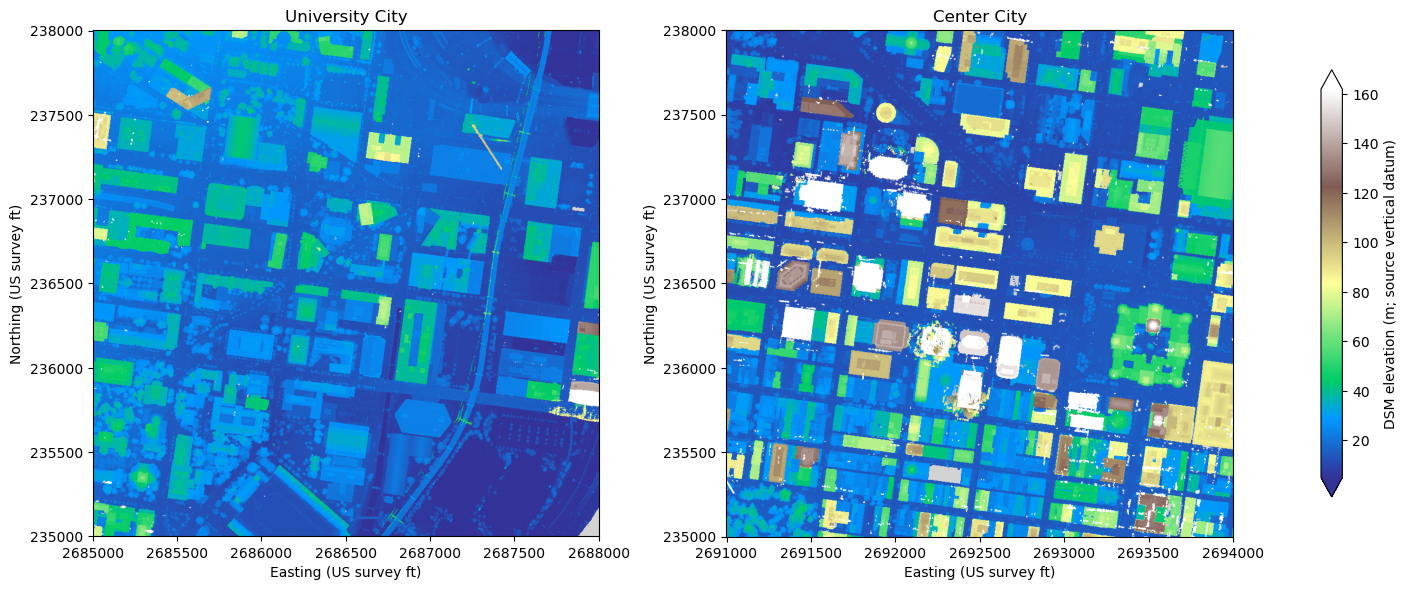

In [9]:
values = np.concatenate([data.compressed() for data, transform in rasters])
vmin, vmax = np.percentile(values, [2, 98])
norm = Normalize(vmin=vmin, vmax=max(vmax, vmin + 1))
cmap = plt.colormaps["terrain"].copy()
cmap.set_bad("lightgray")
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
for ax, case, (data, transform) in zip(axes, cases, rasters):
    show(data, transform=transform, ax=ax, cmap=cmap, norm=norm, adjust=False)
    ax.set(title=case["zone"], xlabel="Easting (US survey ft)", ylabel="Northing (US survey ft)")
    ax.ticklabel_format(style="plain", useOffset=False)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes,
             label="DSM elevation (m; source vertical datum)", shrink=0.75, extend="both")
fig.savefig(OUT / "center_city_university_city_dsm.png", dpi=160)
plt.show()

## Try it

1. Change `CELL_SIZE_M` to 2 and rerun the pipeline and plots. How do gaps and roof detail change?
2. Inspect the tallest pixels: could a maximum represent a tree, roof, or outlier?
3. Explain why these elevations cannot be interpreted as building heights without a matching terrain model.

**Outputs:** two DSM GeoTIFFs, two pipeline JSON files, and a comparison figure in `outputs/lidar/case_studies/`. Raw LAS files remain in the cache. We stop at raster visualization; neither a citywide mosaic nor web-map tiles are needed for this example.